# Working with Text — Assignment 1: TF-IDF from scratch

The assignment consists of 3 questions you will need to answer. You will be creating, from scratch, something akin to the `TfidfVectorizer` in `sklearn`. You can reuse any functions from the lecture notebook if you want, but you don't need them.

## Overview

**Goal:** build a document vectoriser using only Python and NumPy, then use it to find the document that best matches a short query.

**Setup:** `docs[0]` is the *query* ("People who see ghosts") and `docs[-1]` is the *target*, a report about residents who saw ghosts. The documents in between are distractors that share common words such as *people* and *see*.

**Evaluation:** `get_score` (provided by the course) divides the distance from the query to its closest distractor by the distance from the query to the target. **A score above 1 means the target is the query's nearest neighbour.**

**Tools:** Python, NumPy (vectors and distances), NLTK `SnowballStemmer` (stemming), seaborn (distance heatmaps).

| Representation | Score |
|---|---|
| Raw term frequency, no preprocessing | 0.922 |
| Smoothed TF-IDF with cleaning, stemming and stop-word removal | **1.216** |

## Data

In [ ]:
docs = ['People who see ghosts',  # query

        '"I dont believe people who see ghosts", said Mannie, before spitting into the wind and riding his bike down the street at top speed. He then went home and ate peanut-butter and jelly sandwiches all day. Mannie really liked peanut-butter and jelly sandwiches. He ate them so much that his poor mother had to purchase a new jar of peanut butter every afternoon.',

        'People see incredible things. One time I saw some people talking about things they were seeing, and those people were so much fun. They saw clouds and they saw airplanes. They saw dirt and they saw worms. Can you believe the amount of seeing done by these people? People are the best.',

        'This is an article about a circus. A Circus is where people go to see other people who perform great things. Circuses also have elephants and tigers, which generally get a big woop from the crowd.',

        'Lots of people have come down with Coronavirus. You can see the latest numbers and follow our updates on the pandemic below. Please, stay safe.',

        'Goats are lovely creatures. Many people love goats. People who love goats love seeing them play in the fields.',

        'We have collected a report of people in our community seeing ghosts. Each resident was asked "how many ghosts have you seen?", "describe the last ghost you saw", and "tell us about your mother." Afterwards, we compared the ghost reports between the different individuals, and assessed whether or not they were actually seeing these apparitions.']  # target

In [ ]:
# English stop-word list from sebleier: https://gist.github.com/sebleier/554280
stop_words = ["i", "me", "my", "myself", "we", "our", "ours", "ourselves", "you", "your", "yours", "yourself", "yourselves", "he", "him", "his", "himself", "she", "her", "hers", "herself", "it", "its", "itself", "they", "them", "their", "theirs", "themselves", "what", "which", "who", "whom", "this", "that", "these", "those", "am", "is", "are", "was", "were", "be", "been", "being", "have", "has", "had", "having", "do", "does", "did", "doing", "a", "an", "the", "and", "but", "if", "or", "because", "as", "until", "while", "of", "at", "by", "for", "with", "about", "against", "between", "into", "through", "during", "before", "after", "above", "below", "to", "from", "up", "down", "in", "out", "on", "off", "over", "under", "again", "further", "then", "once", "here", "there", "when", "where", "why", "how", "all", "any", "both", "each", "few", "more", "most", "other", "some", "such", "no", "nor", "not", "only", "own", "same", "so", "than", "too", "very", "s", "t", "can", "will", "just", "don", "should", "now"]

# An alternative hand-made list (very frequent / very rare words that looked irrelevant) was also tried:
# stop_words = ['the', 'and', 'a', 'of', 'about', 'i', 'his', 'he', 'them', 'so', 'much', 'can', 'are', 'is', 'our', 'in', 'we', 'dont', 'into', 'at', 'then', 'all', 'new', 'not', 'or', 'us', 'your', 'last', 'each', 'on', 'with', 'lot', 'also', 'an', 'by', 'other', 'this', 'done', 'those', 'some']

## Helper functions

In [ ]:
import re

import numpy as np
import seaborn as sns
from nltk.stem.snowball import SnowballStemmer

sns.set_theme()
stemmer = SnowballStemmer('english')


def preprocess(docs, stop_words=stop_words):
    """Strip punctuation, lowercase, stem and drop stop words.

    Returns a new list; the input list is not modified.
    """
    cleaned = []
    for doc in docs:
        doc = re.sub(r'[^\w|\s]', '', doc)        # remove punctuation
        doc = re.sub(r'\s+', ' ', doc).casefold()  # collapse whitespace, lowercase
        tokens = doc.split(' ')
        # Snowball stemming is not always idempotent, so re-apply it until the tokens stop changing.
        for _ in range(len(tokens)):
            stemmed = [stemmer.stem(word) for word in tokens]
            if stemmed == tokens:
                break
            tokens = stemmed
        cleaned.append(' '.join(word for word in tokens if word not in stop_words))
    return cleaned

In [ ]:
def euclidean_distances(X):
    """Pairwise Euclidean distances between the rows of X."""
    return np.linalg.norm(X[:, None, :] - X[None, :, :], axis=-1)


def cosine_distances(X):
    """Pairwise cosine distances. Rows of X are unit-length, so cosine similarity is just a dot product."""
    return 1 - X @ X.T

In [ ]:
# Scoring function provided with the assignment.
def retrieval_score(vecs):
    """Distance(query, closest distractor) / distance(query, target). Above 1 = target ranked first."""
    dists = euclidean_distances(vecs)
    mxidx = np.argmin(dists[0][1:-1]) + 1
    next_best = np.linalg.norm(vecs[mxidx] - vecs[0])
    target = np.linalg.norm(vecs[-1] - vecs[0])
    return next_best / target


def get_score(vecs):
    print('SCORE: ', retrieval_score(vecs))

In [ ]:
# ###################################################################
#                          ASSIGNMENT
# ###################################################################
#
# Create a class (or function), called "Vectorizer" ("vectorizer").
#
# It should take a list of strings (documents) and turn it into a
# 2D Numpy Array representing the documents as vectors (rows are
# documents). You have flexibility in how exactly they are represented,
# but it should be based on a basic term-frequency vector.
#
# The vectors should be "normalized" such that each row has
# an l2 norm of 1.
#
# NOTE: You are implementing this in pure Python/Numpy


def build_vocabulary(tokenized_docs):
    """Map every word to a column index, in order of first appearance."""
    vocab = {}
    for tokens in tokenized_docs:
        for word in tokens:
            vocab.setdefault(word, len(vocab))
    return vocab


def term_frequency(tokenized_docs, vocab):
    """tf[d, w] = (count of word w in document d) / (number of tokens in d)."""
    tf = np.zeros((len(tokenized_docs), len(vocab)))
    for i, tokens in enumerate(tokenized_docs):
        for word in tokens:
            tf[i, vocab[word]] += 1
        tf[i] /= len(tokens)
    return tf


def document_frequency(docs, tokenized_docs, vocab, substring_match=True):
    """Number of documents that contain each word.

    The submitted version counted a word as present when it appeared anywhere in the document
    string, so 'see' also matched 'seeing'. That stays the default so the scores below match the
    saved outputs. `substring_match=False` uses the usual whole-token definition (see section 3).
    """
    df = np.zeros(len(vocab))
    token_sets = [set(tokens) for tokens in tokenized_docs]
    for word, j in vocab.items():
        if substring_match:
            df[j] = sum(word in doc for doc in docs)
        else:
            df[j] = sum(word in tokens for tokens in token_sets)
    return df


def inverse_document_frequency(df, n_docs, kind='smooth'):
    """IDF variants that were compared; 'smooth' gave the best score.

    Not tried: TF-RF (relevance frequency), which needs class labels:
    https://medium.com/analytics-vidhya/how-good-or-bad-is-traditional-tf-idf-text-mining-technique-304aec920009
    """
    if kind == 'smooth':
        return np.array([np.log(n_docs / (1 + d)) + 1 for d in df])
    if kind == 'standard':
        return np.array([np.log(n_docs / d) for d in df])
    if kind == 'probabilistic':
        return np.array([0.0 if d == n_docs else np.log((n_docs - d) / d) for d in df])
    raise ValueError(f'unknown idf kind: {kind!r}')


def l2_normalize(X):
    """Scale every row to unit L2 norm."""
    return np.vstack([row / np.linalg.norm(row, ord=2) for row in X])


def vectorizer(docs, method='tf', idf='smooth', substring_match=True):
    """Turn a list of strings into a 2D array with one L2-normalised row per document.

    method='tf'    : raw term frequencies, no preprocessing.
    method='tfidf' : preprocessing, then log(1 + tf) weighted by IDF.
    """
    if method == 'tfidf':
        docs = preprocess(docs)
    tokenized = [doc.split(' ') for doc in docs]
    vocab = build_vocabulary(tokenized)
    tf = term_frequency(tokenized, vocab)
    if method == 'tf':
        return l2_normalize(tf)
    if method == 'tfidf':
        df = document_frequency(docs, tokenized, vocab, substring_match)
        return l2_normalize(np.log(1 + tf) * inverse_document_frequency(df, len(docs), idf))
    raise ValueError(f'unknown method: {method!r}')

## 1. Raw term frequency (no preprocessing)

In [ ]:
vec = vectorizer(docs)

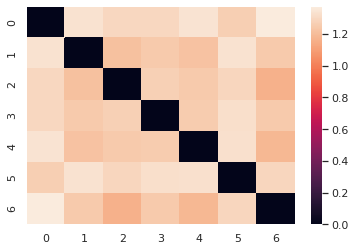

In [ ]:
ax = sns.heatmap(euclidean_distances(vec))

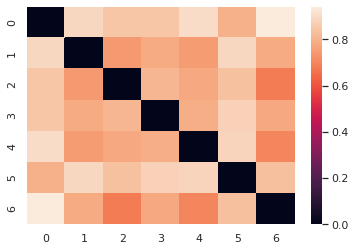

In [ ]:
ax = sns.heatmap(cosine_distances(vec))

Both distance measures rank the documents the same way. That is expected: for unit-length vectors, $\lVert a-b \rVert^2 = 2\,(1-\cos(a,b))$, so Euclidean distance is a monotonic function of cosine distance.

In [ ]:
get_score(vec)

SCORE:  0.9222070615875735


**Score 0.92 (< 1):** with raw counts, a distractor is closer to the query than the target is. Punctuation, capitalisation and very common words such as *people*, *who* and *see* dominate the vectors.

## 2. Smoothed TF-IDF with preprocessing (best setup)

In [ ]:
new_vec = vectorizer(docs, 'tfidf')

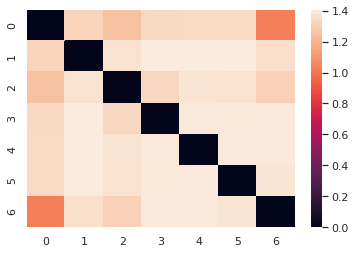

In [ ]:
ax = sns.heatmap(euclidean_distances(new_vec))

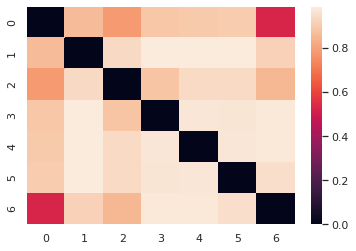

In [ ]:
ax = sns.heatmap(cosine_distances(new_vec))

In [ ]:
get_score(new_vec)

SCORE:  1.216430596980755


**Score 1.22 (> 1):** the target is now the query's nearest neighbour.

Several setups were tried: two stop-word lists, standard / smoothed / probabilistic IDF, and with or without preprocessing. The best combination was:

* **preprocessing:** strip punctuation, lowercase, Snowball stemming (so *see / seeing* and *ghost / ghosts* merge), stop-word removal;
* **weighting:** sublinear TF, $\log(1 + tf)$, multiplied by smoothed IDF, $\log\frac{N}{1 + df} + 1$;
* **normalisation:** each row scaled to unit L2 norm.

## 3. Extra: IDF variants and whole-token document frequency

`document_frequency` above counts a word as present when it appears *anywhere* in a document, so the stem `see` also matches *seeing* and *seen*. The table compares that with the standard whole-token count for each IDF variant. The ranking holds either way: smoothed IDF is best, and the target stays the nearest neighbour (score > 1) in every setup.

In [ ]:
print(f"{'IDF':<15}{'document frequency':<21}score")
for kind in ['smooth', 'standard', 'probabilistic']:
    for substring_match in [True, False]:
        vecs = vectorizer(docs, 'tfidf', idf=kind, substring_match=substring_match)
        label = 'substring' if substring_match else 'whole token'
        print(f'{kind:<15}{label:<21}{retrieval_score(vecs):.3f}')

IDF            document frequency   score
smooth         substring            1.216
smooth         whole token          1.212
standard       substring            1.187
standard       whole token          1.183
probabilistic  substring            1.061
probabilistic  whole token          1.059
